# Codeword-to-layer mapping: Nokia R1-2607066 without SIC

Nokia's RAN1 #126bis contribution R1-2607066 proposes multi-codeword (MCW) PDSCH from rank 2, with up to four codewords. Its link-level evidence is:

| Nokia | Content |
|---|---|
| Fig. 26 | SE vs SNR, fixed rank 1–4, one codeword (NR) vs one codeword per layer, MMSE |
| Fig. 28 | rank 4 with 1, 2 and 4 codewords (here without the SIC curves) |
| Table 3 | rank-transition SNR, SCW vs MCW |
| Table 4 | envelope SE gain of MCW over SCW at −5 / 10 / 20 / 30 dB |

This notebook repeats that evaluation in `nrdlsim` with Nokia's Annex B (Table 11) assumptions, **without the SIC receiver**. It does three things:

1. Explains the modules added for the study (§1–§5).
2. Runs a small live version (§6).
3. Compares the full 400-drop run with Nokia's digitized curves (§7–§9).

Written report: [`docs/cw2lm-nokia.md`](../docs/cw2lm-nokia.md). Full run: `python examples/cw2lm_nokia.py --drops 400` (about 2 min on 4 cores).

In [1]:
import os, sys, json
_p = os.getcwd()
while _p != os.path.dirname(_p) and not os.path.isdir(os.path.join(_p, "nrdlsim")):
    _p = os.path.dirname(_p)
os.chdir(_p); sys.path[:0] = [_p, os.path.join(_p, "examples")]
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, Image, display
%matplotlib inline

from nrdlsim.channel_models import (CDLChannel, _CDL, subarray_factor, rotation_matrix,
                                    element_power_gain, ut_handset_array,
                                    UT_HANDSET_ELEMENT, _element_list_field)
from nrdlsim.layer_mapping import layer_groups
from nrdlsim.link_abstraction import ideal_amc
from nrdlsim.receiver import batch_mmse_sinr, batch_mmse_sinr_est
import cw2lm_nokia as study

SLOT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]; INK2 = "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3df", "font.size": 9.5,
                     "lines.linewidth": 2.0, "legend.frameon": False})

## 0 · The case

Nokia's Table 11 is shown next to what the study uses. Entries marked *assumed* fill gaps in the contribution.

In [2]:
rows = ["| Item | Nokia Table 11 | This study |", "|---|---|---|"]
rows += [f"| {a} | {b} | {c} |" for a, b, c in study.ASSUMPTIONS]
display(Markdown("\n".join(rows)))

| Item | Nokia Table 11 | This study |
|---|---|---|
| Carrier | 3.5 GHz TDD, 30 kHz, 40 MHz | 3.5 GHz, 30 kHz, 96 PRB (rb = 96 in Fig. 26-28) |
| Channel | CDL-A, DS 100 ns, 3 km/h | CDL-A, DS 100 ns, one slot per drop (no CSI ageing) |
| gNB array | 64 TXRU, 192 AE, (12,8,2,1,1;4,8), (dH,dV) = (0.5,0.7) | 64 ports, 3-element vertical TXRU (e-tilt 90 deg), 38.901 element 8 dBi / 65 deg, +-45 deg |
| UE array | 8 Rx, TR 38.901 7.3 (V19.1.0) directive, (a,b,g) = (0,0,0), no blockage | 8 single-pol directive elements on the handset edges (5.4 dBi, 125 deg, 22.5 dB), (0,0,0), no blockage |
| Receiver | MMSE, SIC | LMMSE only (no SIC) |
| Channel estimation | non-ideal | DM-RS estimate, error variance N0/6 per entry |
| Precoding | SU-MIMO | SVD per PRB, equal power per layer |
| Link adaptation | AMC | ideal AMC per codeword: MCS with the most expected bits (MIESM) |
| MCS table | Table 2 (256QAM) | Table 2 (256QAM) |
| Rank | fixed 1, 2, 3, 4 | fixed 1, 2, 3, 4 |
| Overhead | - | 2 PDCCH + 2 DM-RS symbols, 120 RE/PRB: 4.94 bit/s/Hz per layer at MCS 27 (Nokia: 5.0) |

## 1 · gNB array: 38.901 element and 3-element TXRU sub-array

The gNB has (M, N, P; Mp, Np) = (12, 8, 2; 4, 8): 192 elements driven by 64 TXRUs, each feeding 3 vertical elements 0.7 λ apart. `CDLChannel(tx_subarray=3, tx_etilt_deg=90)` builds 64 ports whose rows are 2.1 λ apart. Each port pattern is the element pattern times the sub-array factor (`subarray_factor`):

$$w_k = \tfrac{1}{\sqrt K} e^{-j 2\pi k d_V \cos\theta_{etilt}},\qquad AF(\theta) = \sum_k w_k\, e^{j 2\pi k d_V \cos\theta}.$$

Both the sectored element (horizontal) and the sub-array (vertical) filter CDL-A's clusters. The bars show each cluster's power after the gNB port gain, relative to the table power.

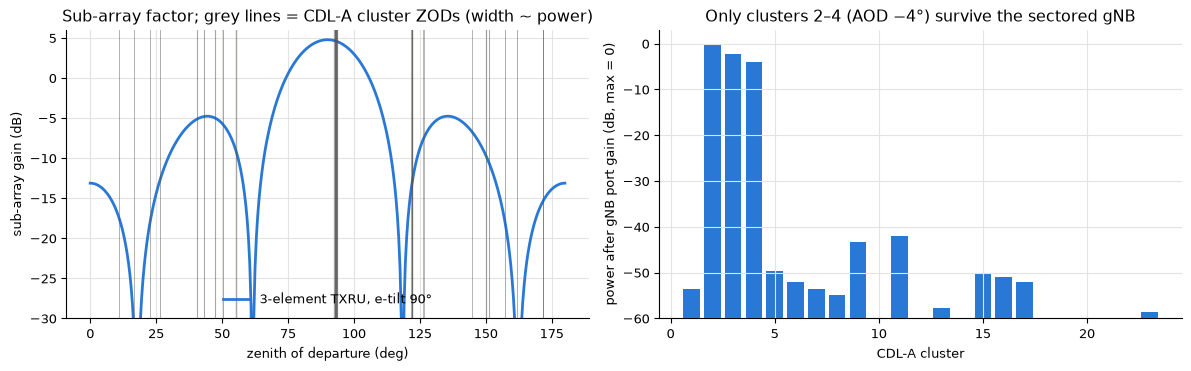

In [3]:
cl = np.array(_CDL["CDL-A"]["clusters"])
R = rotation_matrix()
zen = np.linspace(0, 180, 361)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(zen, 10*np.log10(np.abs(subarray_factor(np.zeros_like(zen), zen, R, 3, 0.7, 90.0))**2 + 1e-9),
           color=SLOT[0], label="3-element TXRU, e-tilt 90°")
for z, p in zip(cl[:, 4], cl[:, 1]):
    ax[0].axvline(z, color=INK2, lw=0.6 + 2.5 * 10**(p/10), alpha=0.5)
ax[0].set(xlabel="zenith of departure (deg)", ylabel="sub-array gain (dB)", ylim=(-30, 6),
          title="Sub-array factor; grey lines = CDL-A cluster ZODs (width ~ power)")
ax[0].legend(loc="lower center")
g_el = element_power_gain(cl[:, 2], cl[:, 4])
g_sa = np.abs(subarray_factor(cl[:, 2], cl[:, 4], R, 3, 0.7, 90.0))**2
port = 10*np.log10(g_el * g_sa)
rel = cl[:, 1] + port - (cl[:, 1] + port).max()
ax[1].bar(np.arange(1, len(cl)+1), np.maximum(rel, -60) + 60, bottom=-60, color=SLOT[0])
ax[1].set(xlabel="CDL-A cluster", ylabel="power after gNB port gain (dB, max = 0)",
          title="Only clusters 2–4 (AOD −4°) survive the sectored gNB", ylim=(-60, 3))
plt.tight_layout(); plt.show()

## 2 · UE: 8-element edge-mounted handset (`ut_handset_array`)

The study models TR 38.901 §7.3 (V19.1.0) "directive antennas" as follows:
- 8 single-polarized elements on the edges of a 15 × 7 cm handset, two per edge.
- Each element points out of its edge, with the broad directional pattern used for the 7–24 GHz UE (5.4 dBi, 125°, 22.5 dB).
- Polarization alternates between θ and φ along each edge.
- The device stands upright facing azimuth 0, so (α, β, γ) = (0, 0, 0).

This layout is reconstructed from memory of the Rel-19 model and is *assumed*. `CDLChannel(rx_elements=...)` accepts any element list with per-element position, orientation and polarization.

| # | y (cm) | z (cm) | boresight (bearing, downtilt) | ζ |
|---|---|---|---|---|
| 1 | -1.8 | +7.5 | (+0°, -90°) | 0° |
| 2 | +1.8 | +7.5 | (+0°, -90°) | 90° |
| 3 | +3.5 | +3.8 | (+90°, +0°) | 0° |
| 4 | +3.5 | -3.8 | (+90°, +0°) | 90° |
| 5 | +1.8 | -7.5 | (+0°, +90°) | 0° |
| 6 | -1.8 | -7.5 | (+0°, +90°) | 90° |
| 7 | -3.5 | -3.8 | (-90°, +0°) | 0° |
| 8 | -3.5 | +3.8 | (-90°, +0°) | 90° |

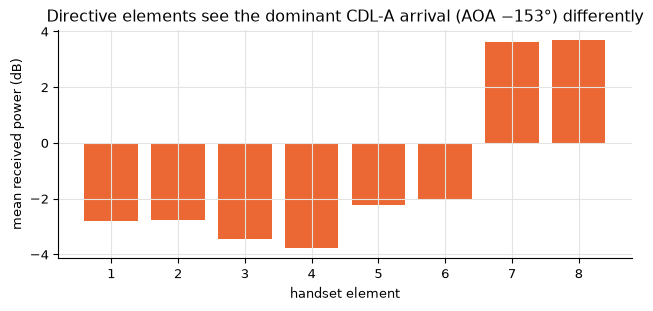

In [4]:
ue = ut_handset_array(3.5e9)
lam = 3e8 / 3.5e9
rows = ["| # | y (cm) | z (cm) | boresight (bearing, downtilt) | ζ |", "|---|---|---|---|---|"]
for i, (p, r, z) in enumerate(zip(ue["positions"], ue["rotation_deg"], ue["pol_slant_deg"]), 1):
    rows.append(f"| {i} | {100*p[1]*lam:+.1f} | {100*p[2]*lam:+.1f} | ({r[0]:+.0f}°, {r[1]:+.0f}°) | {z:.0f}° |")
display(Markdown("\n".join(rows)))

# mean received power per element over 100 CDL-A drops (gNB 64T as in the study)
p = np.zeros(8)
f = (np.arange(16) - 8) * 12 * 30e3 * 6
for seed in range(100):
    H = study.make_channel(seed, "handset").frequency_response(f, 0.0)
    p += (np.abs(H)**2).mean((0, 2)) / 100
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.bar(np.arange(1, 9), 10*np.log10(p), color=SLOT[1])
ax.set(xlabel="handset element", ylabel="mean received power (dB)",
       title="Directive elements see the dominant CDL-A arrival (AOA −153°) differently")
plt.tight_layout(); plt.show()

## 3 · Eigenmodes, precoding and the MMSE receiver with a channel estimate

The precoder is SVD per PRB with equal power per layer. The rank-r effective channel is then $HW = U_r\,\mathrm{diag}(s_r)/\sqrt r$, and with perfect channel knowledge layer k has SINR $s_k^2\,\mathrm{SNR}/r$.

Channel estimation is modelled as $\hat H = HW + E$, with $E$ of variance $N_0/6$ per entry. `batch_mmse_sinr_est` builds the LMMSE filter on $\hat H$ and evaluates signal, inter-layer leakage and noise on the true $HW$.

The eigenvalue spread $s_1^2 / s_k^2$ is the layer imbalance.

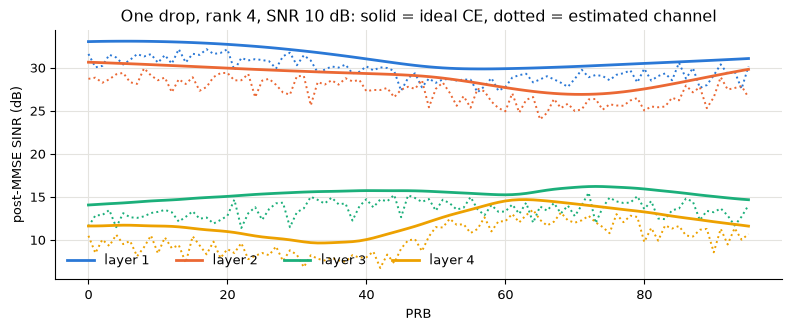

mean eigenvalues (dB): [27.4 25.1 11.4  8.3]


In [5]:
U, s = study.drop_eigenmodes(0, "handset")
n0 = 10**(-10/10)                                   # 10 dB on our SNR scale
h = U * (s[:, None, :] / 2.0)                       # rank 4
rng = np.random.default_rng(0)
E = np.sqrt(n0/6/2) * (rng.standard_normal(h.shape) + 1j*rng.standard_normal(h.shape))
ideal = 10*np.log10(batch_mmse_sinr(h, n0)); est = 10*np.log10(batch_mmse_sinr_est(h, h + E, n0))
fig, ax = plt.subplots(figsize=(8, 3.4))
for k in range(4):
    ax.plot(ideal[:, k], color=SLOT[k], label=f"layer {k+1}")
    ax.plot(est[:, k], color=SLOT[k], ls=":", lw=1.4)
ax.set(xlabel="PRB", ylabel="post-MMSE SINR (dB)",
       title="One drop, rank 4, SNR 10 dB: solid = ideal CE, dotted = estimated channel")
ax.legend(ncol=4, loc="lower left"); plt.tight_layout(); plt.show()
print("mean eigenvalues (dB):", np.round(10*np.log10((s**2).mean(0)), 1))

## 4 · Codeword-to-layer mapping and ideal AMC

`layer_groups(r, max_cw)` splits r layers into min(r, max_cw) contiguous groups, smaller groups first; for two codewords this is NR's split for ranks 5–8.

`ideal_amc` picks, for each codeword, the MCS (Table 2) with the most expected bits, TBS·(1−BLER). The BLER comes from MIESM over the codeword's layers and the LDPC waterfall.

A single codeword gets the mean mutual information of its layers at one modulation order. So it loses only when the layers differ.

In [6]:
print({r: {c: layer_groups(r, c) for c in (1, 2, 4)} for r in (2, 3, 4)})
def se(sinr_db, max_cw):
    x = 10**(np.repeat(np.asarray(sinr_db, float)[None], 96, 0) / 10)
    bits = sum(ideal_amc(x[:, g].ravel(), len(g), study.N_RE, 96)[3]
               for g in layer_groups(x.shape[1], max_cw))
    return bits / study.SLOT / study.BW
for case in ([15, 15, 15, 15], [25, 15, 5, -5], [40, 22, 7, -2]):
    print(f"layer SINRs {case} dB:  1 CW {se(case, 1):5.2f}   2 CW {se(case, 2):5.2f}   "
          f"1 CW/layer {se(case, 4):5.2f} bit/s/Hz")

{2: {1: [[0, 1]], 2: [[0], [1]], 4: [[0], [1]]}, 3: {1: [[0, 1, 2]], 2: [[0], [1, 2]], 4: [[0], [1], [2]]}, 4: {1: [[0, 1, 2, 3]], 2: [[0, 1], [2, 3]], 4: [[0], [1], [2], [3]]}}
layer SINRs [15, 15, 15, 15] dB:  1 CW  9.71   2 CW  9.70   1 CW/layer  9.69 bit/s/Hz
layer SINRs [25, 15, 5, -5] dB:  1 CW  5.35   2 CW  6.77   1 CW/layer  7.86 bit/s/Hz
layer SINRs [40, 22, 7, -2] dB:  1 CW  7.93   2 CW  9.41   1 CW/layer 10.04 bit/s/Hz


## 5 · The study loop

For every drop, `examples/cw2lm_nokia.py`:

1. draws a CDL-A channel;
2. takes the SVD on every PRB;
3. for each SNR and rank, computes the per-layer SINR with the estimated channel;
4. runs ideal AMC for each codeword grouping.

The same drops and estimation noise are used for every mapping (common random numbers). After the run:
- our SNR axis is aligned to Nokia's on the rank-1 curve, which no codeword mapping can change;
- the Nokia metrics are computed on that axis: Table 3 transitions, Table 4 envelope gains and the rank-4 gains.

## 6 · Live mini-run (24 drops, Nokia set-up)

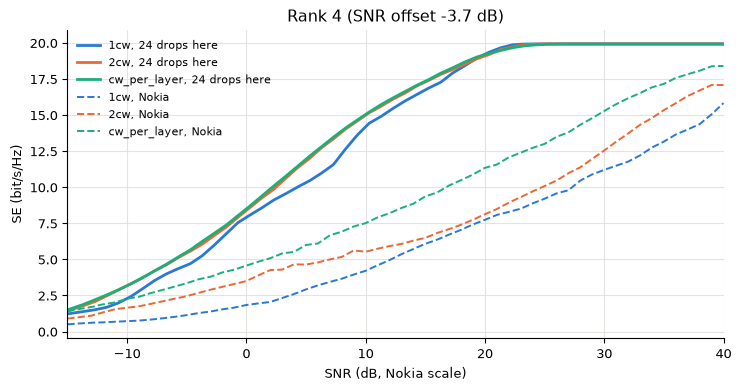

In [7]:
mini = study.run_variant("nokia", 24, 4)
nsnr, ncur, n28 = study.nokia_curves()
delta = study.snr_offset(study.SNRS, mini["se"]["1cw"]["1"], nsnr, ncur["1cw"]["1"])
snr = study.SNRS + delta
fig, ax = plt.subplots(figsize=(7.5, 4))
for i, m in enumerate(("1cw", "2cw", "cw_per_layer")):
    ax.plot(snr, mini["se"][m]["4"], color=SLOT[i], label=f"{m}, 24 drops here")
ax.plot(nsnr, ncur["1cw"]["4"], color=SLOT[0], ls="--", lw=1.4, label="1cw, Nokia")
ax.plot(nsnr, n28["2cw"], color=SLOT[1], ls="--", lw=1.4, label="2cw, Nokia")
ax.plot(nsnr, ncur["cw_per_layer"]["4"], color=SLOT[2], ls="--", lw=1.4, label="cw_per_layer, Nokia")
ax.set(xlim=(-15, 40), xlabel="SNR (dB, Nokia scale)", ylabel="SE (bit/s/Hz)",
       title=f"Rank 4 (SNR offset {delta:+.1f} dB)")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

## 7 · Full run (400 drops): Fig. 26 and Fig. 28 equivalents

The figures and tables below come from the saved run in `results/cw2lm_nokia.json`.
- Panel (a) is this simulator with the Nokia set-up; panel (b) is Nokia's digitized Fig. 26.
- Panel (c) is the diagnostic of §9.
- Panel (d) shows the gain of the best-rank envelope.

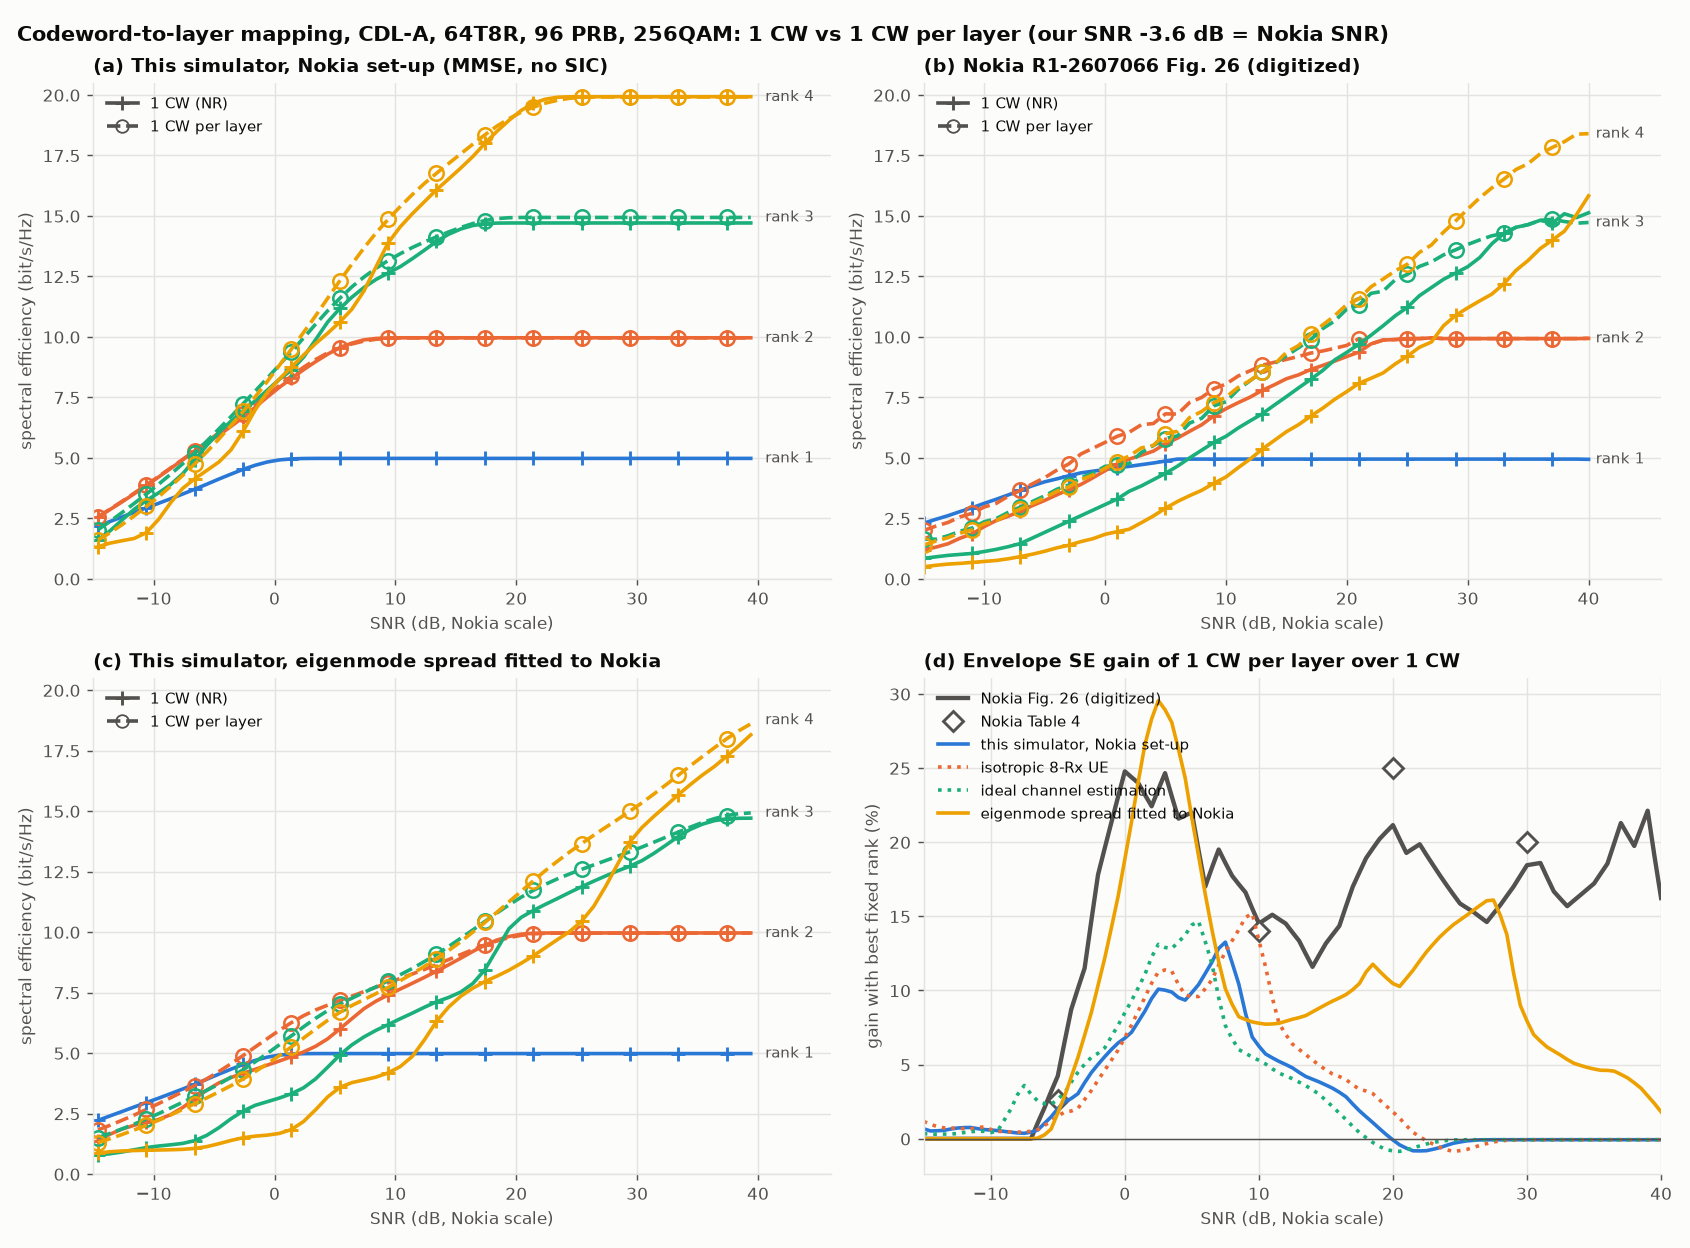

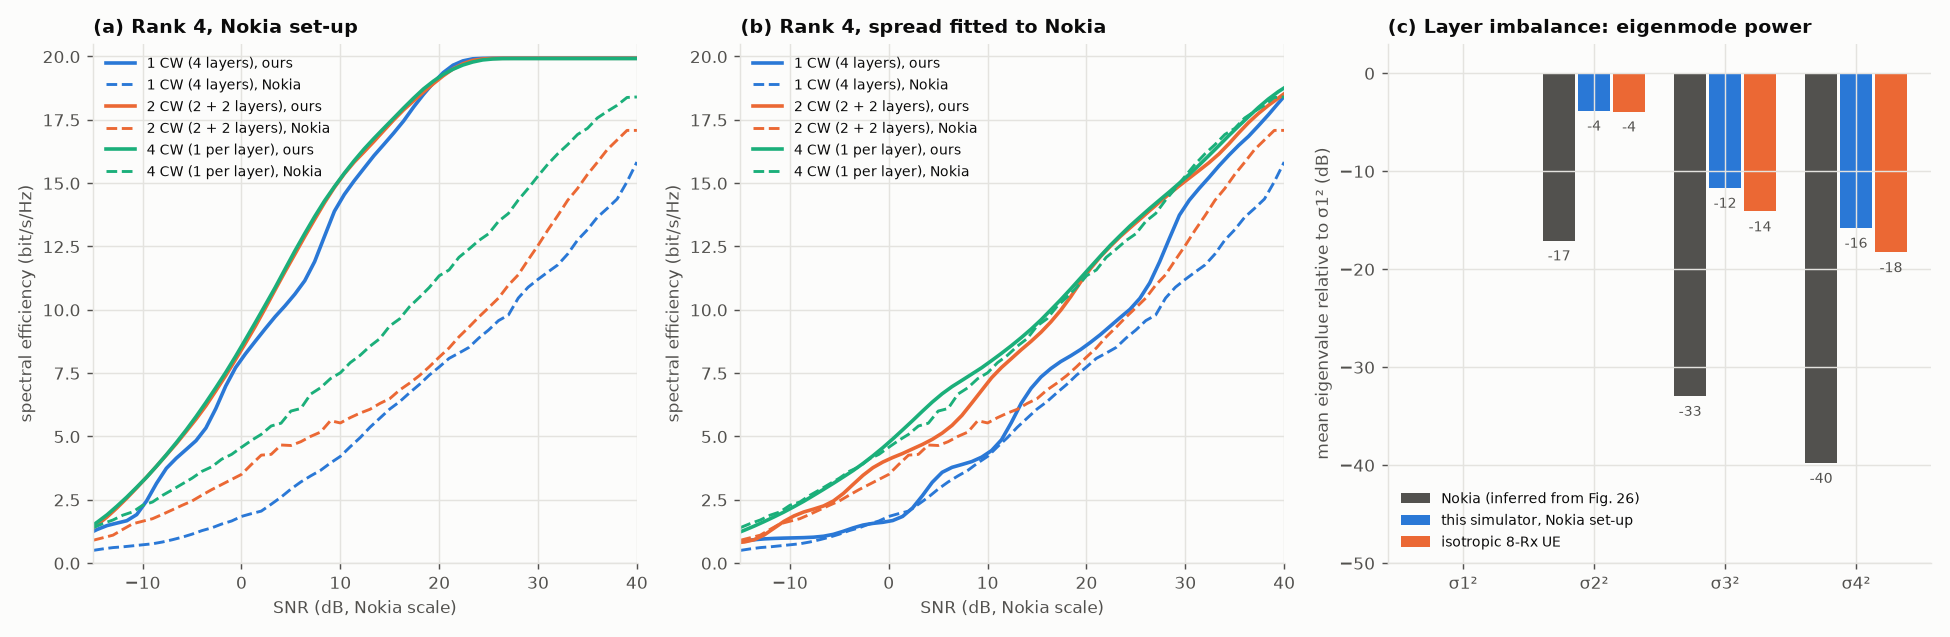

In [8]:
res = json.load(open("results/cw2lm_nokia.json")); cmp = res["comparison"]
display(Image("results/cw2lm_nokia.png", width=1000))
display(Image("results/cw2lm_nokia_rank4.png", width=1000))

## 8 · Tables 3 and 4: Nokia vs this simulator

In [9]:
f = lambda xs: " / ".join("n/a" if x is None else f"{x:.1f}" for x in xs)
rows = ["| | Table 3: 1→2 / 2→3 / 3→4 (dB) | Table 4: gain at −5 / 10 / 20 / 30 dB (%) |", "|---|---|---|",
        f"| Nokia, 1 CW | {f(study.NOKIA_TABLE3['1cw'])} | |",
        f"| Nokia, CW per layer | {f(study.NOKIA_TABLE3['cw_per_layer'])} | {f(study.NOKIA_TABLE4['cw_per_layer'])} |"]
for name in ("nokia", "iso_ue", "ideal_ce", "matched"):
    c = cmp[name]
    rows.append(f"| {res['variants'][name]['label']}, 1 CW | {f(c['table3']['1cw'])} | |")
    rows.append(f"| {res['variants'][name]['label']}, CW per layer | {f(c['table3']['cw_per_layer'])} | "
                f"{f(c['table4_pct']['cw_per_layer'])} |")
display(Markdown("\n".join(rows)))
rows = ["| Rank 4, gain over 1 CW at −5 / 10 / 20 / 30 dB (%) | 2 CW | 4 CW |", "|---|---|---|",
        f"| Nokia (digitized) | {f(cmp['nokia_digitized']['rank4_gain_pct']['2cw'])} | "
        f"{f(cmp['nokia_digitized']['rank4_gain_pct']['cw_per_layer'])} |"]
for name in ("nokia", "matched"):
    c = cmp[name]["rank4_gain_pct"]
    rows.append(f"| {res['variants'][name]['label']} | {f(c['2cw'])} | {f(c['cw_per_layer'])} |")
display(Markdown("\n".join(rows)))
print(f"SNR offset: our SNR {cmp['snr_offset_db']:+.1f} dB = Nokia SNR")

| | Table 3: 1→2 / 2→3 / 3→4 (dB) | Table 4: gain at −5 / 10 / 20 / 30 dB (%) |
|---|---|---|
| Nokia, 1 CW | 0.0 / 19.0 / 38.0 | |
| Nokia, CW per layer | -7.0 / 14.0 / 17.0 | 2.6 / 14.0 / 25.0 / 20.0 |
| Nokia set-up (8-Rx directive handset, non-ideal CE), 1 CW | -17.1 / -5.1 / 7.6 | |
| Nokia set-up (8-Rx directive handset, non-ideal CE), CW per layer | -17.6 / -5.9 / 0.5 | 2.0 / 6.2 / -0.1 / -0.1 |
| isotropic 8-Rx UE (2x2 dual-pol), non-ideal CE, 1 CW | -17.2 / 2.8 / 9.6 | |
| isotropic 8-Rx UE (2x2 dual-pol), non-ideal CE, CW per layer | -17.7 / -3.4 / 3.0 | 1.5 / 13.4 / 1.8 / -0.1 |
| 8-Rx directive handset, ideal CE, 1 CW | -18.6 / -7.5 / 5.5 | |
| 8-Rx directive handset, ideal CE, CW per layer | -18.6 / -9.4 / -3.4 | 2.7 / 5.3 / -0.8 / -0.1 |
| eigenmode spread fitted to Nokia's MCW curves, ideal CE, 1 CW | 2.0 / 18.9 / 28.0 | |
| eigenmode spread fitted to Nokia's MCW curves, ideal CE, CW per layer | -5.8 / 8.1 / 18.0 | 1.7 / 7.8 / 10.5 / 7.9 |

| Rank 4, gain over 1 CW at −5 / 10 / 20 / 30 dB (%) | 2 CW | 4 CW |
|---|---|---|
| Nokia (digitized) | 114.9 / 31.4 / 5.0 / 12.0 | 193.9 / 78.4 / 46.5 / 36.4 |
| Nokia set-up (8-Rx directive handset, non-ideal CE) | 16.9 / 6.1 / -0.5 / -0.0 | 18.7 / 6.2 / -0.1 / -0.1 |
| eigenmode spread fitted to Nokia's MCW curves, ideal CE | 118.0 / 64.1 / 32.7 / 7.0 | 173.6 / 81.7 / 33.9 / 7.9 |

SNR offset: our SNR -3.6 dB = Nokia SNR


## 9 · Why the gains differ: layer imbalance, and the diagnostic

With SVD precoding, the 1-CW-per-layer curves determine the eigenvalue spread. Nokia's curves imply a second eigenmode about 17 dB below the first. The handset modelled here gives about 4 dB, because the ±45° gNB polarizations give a second strong mode on the dominant cluster.

The diagnostic variant `matched` imposes Nokia's spread on our drops. It scales eigenmodes 2–4 down so that only the 1-CW-per-layer curves match Nokia's; the 1-CW and 2-CW curves are predictions.

In [10]:
for name in ("nokia", "iso_ue", "matched"):
    v = res["variants"][name]; e = np.array(v["eig_db_mean"])
    print(f"{v['label'][:60]:60s} sigma_k^2/sigma_1^2 (dB): {np.round(e - e[0], 1)}")
print("fitted extra attenuation of eigenmodes 1-4 (dB):", res["variants"]["matched"]["eig_atten_db"])

Nokia set-up (8-Rx directive handset, non-ideal CE)          sigma_k^2/sigma_1^2 (dB): [  0.   -3.8 -11.7 -15.8]
isotropic 8-Rx UE (2x2 dual-pol), non-ideal CE               sigma_k^2/sigma_1^2 (dB): [  0.   -3.9 -14.1 -18.3]
eigenmode spread fitted to Nokia's MCW curves, ideal CE      sigma_k^2/sigma_1^2 (dB): [  0.  -17.1 -33.  -39.8]
fitted extra attenuation of eigenmodes 1-4 (dB): [0.0, 13.25, 21.25, 24.0]


## 10 · Conclusions

- **Qualitatively Nokia's results are reproduced.** One codeword per layer is never worse than one codeword. Its gain grows with rank and with layer imbalance. Two codewords sit between one and four at rank 4. Multi-codeword mapping moves the rank transitions to lower SNR. The gain disappears once every layer reaches the top MCS.
- **Quantitatively not, with this simulator's own channel.** The envelope gain is about 6 % at 10 dB and zero from 20 dB, against Nokia's 14–25 %. Our CDL-A / 64T / handset layers are far more balanced: σ2² is −4 dB against about −17 dB.
- **With Nokia's imbalance imposed**, the single-codeword curves and the rank-4 gains of 4 codewords follow Nokia's up to about 15 dB. Above that, and for 2 codewords, our MIESM model credits a codeword spanning very unequal layers with more than Nokia's results show. This is likely a limit of mutual-information averaging at 256QAM and high code rate, but it is not verified: the bit-true LDPC path here is a toy code.
- **The multi-codeword gain is set mainly by the layer imbalance**, as Nokia argue (Observation 36, Proposals 43–44). The UE antenna model, here an assumed reconstruction of TR 38.901 V19.1.0 §7.3, should be checked before a system-level comparison.